# Vorlesungsnotebook zur Erweiterung der Linearen Regression, Regularisierung und Merkmalnormierung




In [1]:
import numpy as np
from matplotlib import pylab
import pylab as plt
import numpy as np

## Polynomregression

In [2]:
m=100
X = 6 * np.random.rand(m,1)-3
y =  X**2 + X*2 + np.random.randn(m,1)

Text(0.5, 1.0, 'scatter plot')

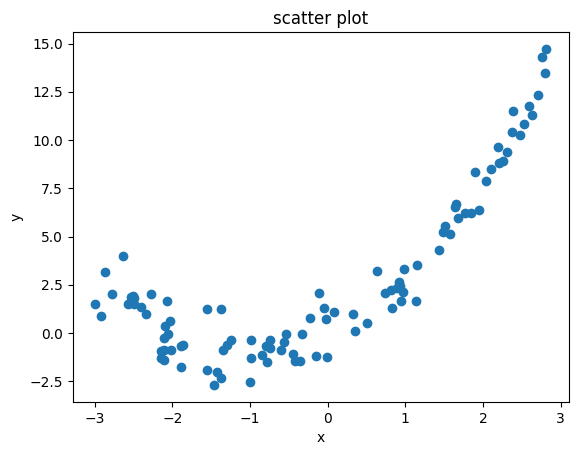

In [3]:
plt.scatter(X,y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('scatter plot')

In [4]:
class MyLinReg:
    
    def fit(self,X,y):
        X_w = np.c_[np.ones((100,1)),X]
        self.weights_ = np.linalg.inv(X_w.T.dot(X_w)).dot(X_w.T).dot(y)
        
        
    def predict(self, Xpred):
        
        X_tmp = np.c_[np.ones((Xpred.shape[0],1)),Xpred]
        y_predict = X_tmp.dot(self.weights_)
        return y_predict
    


In [5]:
mlr = MyLinReg()

mlr.fit(X,y)

In [6]:
print(mlr.weights_)

[[3.02678378]
 [1.87835977]]


In [7]:
X_new = np.array([[-3],[3]])

y_pred = mlr.predict(X_new)



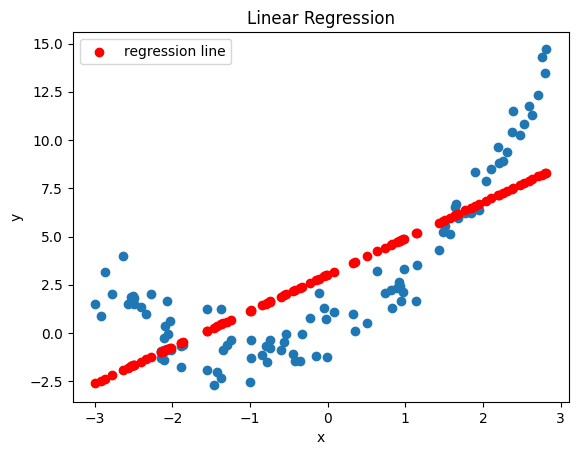

In [8]:
plt.scatter(X,y)
plt.scatter(X,mlr.predict(X),c='red', label='regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Regression')
plt.legend()

In [9]:
from sklearn.preprocessing import PolynomialFeatures

In [10]:
poly_features = PolynomialFeatures(degree =2, include_bias=False)
X_poly = poly_features.fit_transform(X)

print(X[0])
print(X_poly[0])

print(X.shape)
print(X_poly.shape)

[-2.49673194]
[-2.49673194  6.23367039]
(100, 1)
(100, 2)


In [11]:
mlr_poly = MyLinReg()

mlr_poly.fit(X_poly,y)

In [12]:
print(mlr_poly.weights_)

[[-0.0768384 ]
 [ 1.99264173]
 [ 0.99711447]]


In [13]:
X_new_poly = poly_features.fit_transform(X_new)


y_pred_poly = mlr_poly.predict(X_new_poly)


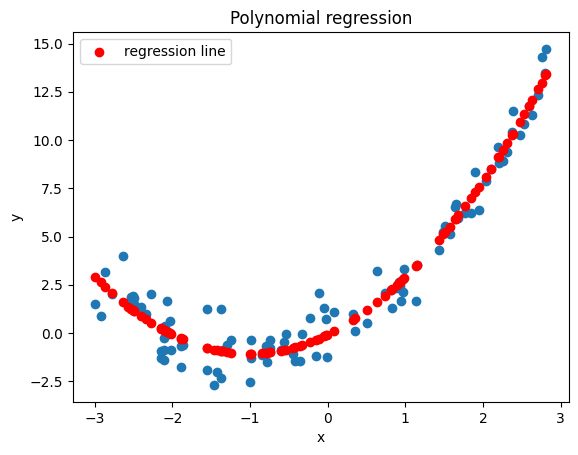

In [14]:

plt.scatter(X,y)
plt.scatter(X,mlr_poly.predict(X_poly),c='red', label='regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial regression')
plt.legend()

In [15]:
poly20_features = PolynomialFeatures(degree =20, include_bias=False)
X_poly20 = poly20_features.fit_transform(X)

print(X[0])
print(X_poly20[0])

[-2.49673194]
[-2.49673194e+00  6.23367039e+00 -1.55638040e+01  3.88586465e+01
 -9.70196239e+01  2.42231994e+02 -6.04788357e+02  1.50999441e+03
 -3.77005127e+03  9.41280742e+03 -2.35012570e+04  5.86763389e+04
 -1.46499090e+05  3.65768956e+05 -9.13227036e+05  2.28008311e+06
 -5.69275633e+06  1.42132866e+07 -3.54867666e+07  8.86009436e+07]


In [16]:
mlr_poly20 = MyLinReg()

mlr_poly20.fit(X_poly20,y)

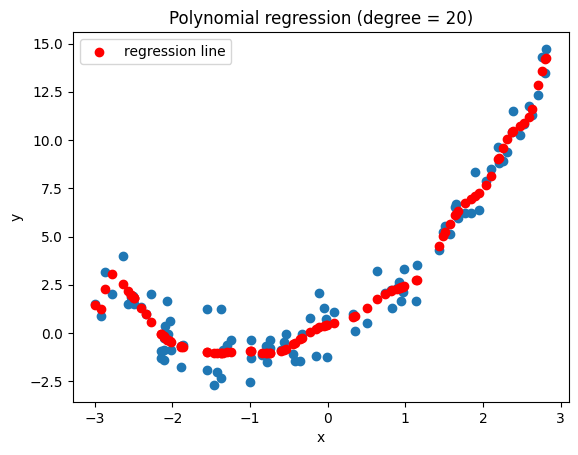

In [17]:
plt.scatter(X,y)
plt.scatter(X,mlr_poly20.predict(X_poly20),c='red', label='regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial regression (degree = 20)')
plt.legend()

## Regularisierung

In [60]:
##### from sklearn import linear_model

#hier Ridge-Regression

clf = linear_model.Ridge(alpha=0.1)
clf.fit(X_poly20,y)

/Users/bockletto/venv_base/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.80905e-21): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Ridge(alpha=0.1)

In [61]:
print(clf.coef_)

[[ 1.98274649e+00  5.05215607e-02  8.14733381e-03  7.01098781e-02
  -4.67931646e-01  7.49817030e-02  1.56927930e-01  3.23617982e-01
   2.87882285e-01 -2.85453037e-01 -2.32844129e-01  9.37583515e-02
   7.27814790e-02 -1.45577419e-02 -1.14567482e-02  9.90116630e-04
   9.04377350e-04 -9.89983231e-06 -2.85016277e-05 -1.24635565e-06]]


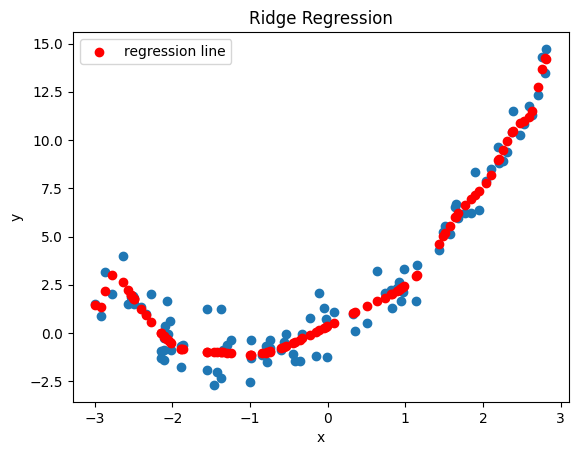

In [62]:
plt.scatter(X,y)
plt.scatter(X,clf.predict(X_poly20),c='red', label='regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Ridge Regression')
plt.legend()

In [56]:

#hier Lasso-Regression

clf = linear_model.Lasso(alpha=0.1)
clf.fit(X_poly20,y)

/Users/bockletto/venv_base/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.702e+01, tolerance: 1.832e-01
  model = cd_fast.enet_coordinate_descent(


Lasso(alpha=0.1)

In [51]:
print(clf.coef_) #Sehr geringe Gewichte der hohen Koeffizienten

[ 1.23576035e+00  0.00000000e+00  3.34325087e-01  2.49578253e-01
  0.00000000e+00 -2.85883768e-03 -6.84908318e-03 -2.04873184e-03
 -2.64850421e-04 -6.15490115e-05  1.41129541e-05  6.42400400e-07
  3.20428651e-06  4.01652604e-07  3.56958527e-07  6.17833853e-08
  3.14552840e-08  7.99136489e-09  2.23183788e-09  9.64766724e-10]


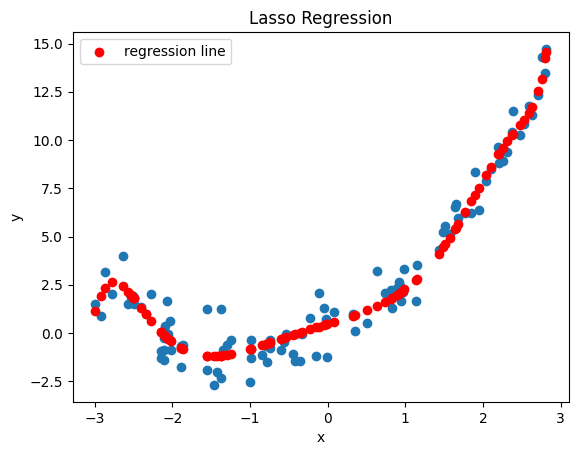

In [52]:
plt.scatter(X,y)
plt.scatter(X,clf.predict(X_poly20),c='red', label='regression line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Lasso Regression')
plt.legend()


In [53]:
from matplotlib import pylab
import pylab as plt
import numpy as np



.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

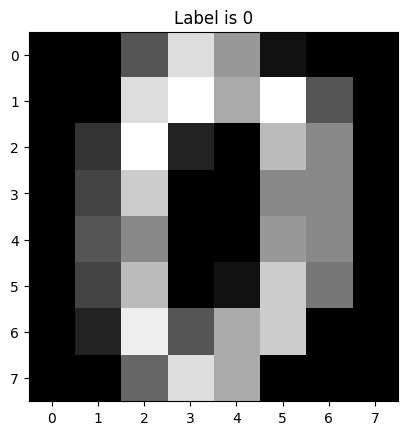

In [25]:


from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn import datasets
from skimage import exposure
import numpy as np
import matplotlib.pyplot as plt

# load the MNIST digits dataset
mnist = datasets.load_digits()


print(mnist["DESCR"])

# take the MNIST data and construct the training and testing split, using 75% of the
# data for training and 25% for testing

(Xtr, Xte, ytr, yte) = train_test_split(np.array(mnist.data),
mnist.target, test_size=0.25, random_state=42)
print(mnist.data[0].shape)
pixels = np.array(mnist.data[0], dtype='uint8')
pixels = pixels.reshape((8, 8))
plt.title('Label is {label}'.format(label=mnist.target[0]))
plt.imshow(pixels, cmap='gray')
plt.show()





In [26]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(solver='liblinear')

model.fit(Xtr, ytr)
o = model.predict(Xte)



import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))







0.9666666666666667
Confusion Matrix
[[42  0  0  0  1  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  1  0]
 [ 0  0 38  0  0  0  0  0  0  0]
 [ 0  0  0 44  0  1  0  0  1  0]
 [ 0  1  0  0 54  0  0  0  0  0]
 [ 0  0  1  0  0 56  0  0  1  1]
 [ 0  0  0  0  0  1 44  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  1]
 [ 0  1  0  0  0  1  0  0 36  0]
 [ 0  0  0  0  0  0  0  0  3 45]]


# Merkmalnormierung


In [27]:
from sklearn.preprocessing import MinMaxScaler
data = [[-1, 2], [-0.5, 6], [0, 10], [1, 18]]

scaler = MinMaxScaler()
scaler.fit(data)
#print(scaler.fit(data))

print("min,max:")
print(scaler.data_max_)
print(scaler.data_min_)

print("transformed:")

print(scaler.transform(data))



min,max:
[ 1. 18.]
[-1.  2.]
transformed:
[[0.   0.  ]
 [0.25 0.25]
 [0.5  0.5 ]
 [1.   1.  ]]


In [28]:
myscaler = MinMaxScaler()
myscaler.fit(Xtr)
Xtr_minmax=myscaler.transform(Xtr)
Xte_minmax=myscaler.transform(Xte)


model = LogisticRegression(solver='liblinear')

model.fit(Xtr_minmax, ytr)
o = model.predict(Xte_minmax)



import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))


0.9622222222222222
Confusion Matrix
[[43  0  0  0  0  0  0  0  0  0]
 [ 0 35  2  0  0  0  0  0  0  0]
 [ 0  0 38  0  0  0  0  0  0  0]
 [ 0  0  0 42  0  1  0  0  3  0]
 [ 0  1  0  0 54  0  0  0  0  0]
 [ 0  0  0  0  0 56  1  0  0  2]
 [ 0  0  0  0  0  1 44  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  1]
 [ 0  1  0  0  0  1  0  0 36  0]
 [ 0  0  0  0  0  1  0  0  2 45]]


In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(Xtr)

Xtr_std = scaler.transform(Xtr)
Xte_std = scaler.transform(Xte)


model = LogisticRegression(solver='liblinear')

model.fit(Xtr_std, ytr)
o = model.predict(Xte_std)


import sklearn.metrics as eval
acc=eval.accuracy_score(yte,o)

print(acc)
print("Confusion Matrix")
print(eval.confusion_matrix(yte,o))



0.9666666666666667
Confusion Matrix
[[43  0  0  0  0  0  0  0  0  0]
 [ 0 36  1  0  0  0  0  0  0  0]
 [ 0  0 38  0  0  0  0  0  0  0]
 [ 0  0  0 43  0  1  0  0  2  0]
 [ 0  1  0  0 54  0  0  0  0  0]
 [ 0  0  0  0  0 57  1  0  0  1]
 [ 0  0  0  0  0  1 44  0  0  0]
 [ 0  0  0  0  0  0  0 40  0  1]
 [ 0  2  0  0  0  1  0  0 35  0]
 [ 0  0  0  0  0  1  0  0  2 45]]
